# Shift-and-Stack on Detection Catalogues

*Matthew Payne*

Survey pipelines normally keep only detections with a signal-to-noise ratio (S/N) of at least 5 in a single image, to keep their catalogues pure. That throws away the faintest moving objects. *Shift-and-stack* recovers them: add up many images along a trial trajectory, and an object moving along it adds coherently while the noise averages down, so $N$ images reach $\sqrt N$ times deeper. Its cost is the problem: every pixel of every image is shifted and added for every trial velocity, and the number of velocities grows rapidly for fast-moving objects.

This notebook reproduces, on a simulated survey, the method of

> S. Stetzler, M. Jurić, P. H. Bernardinelli et al. (2025), *An Efficient Shift-and-stack Algorithm Applied to Detection Catalogs*, AJ **170**, 352. [ADS](https://ui.adsabs.harvard.edu/abs/2025AJ....170..352S/abstract) · [arXiv:2509.26279](https://arxiv.org/abs/2509.26279)

which we refer to as S25. Their idea: run source detection at a *low* threshold (S/N of 2 or 3, say), producing a catalogue dominated by noise peaks, and then shift and stack the *catalogue* rather than the pixels. Catalogues are sparse, so far fewer operations are needed, and coarser stacking bins mean fewer trial velocities.

We will:

1. Simulate a short survey: 30 difference images over 4 hours, with white noise, a Gaussian PSF and faint moving objects.
2. Detect sources at low thresholds, and compare the number of noise peaks with the theory that S25 use.
3. Use S25's statistics to choose the stacking bin $\Delta x$ and the minimum cluster size $N_{\rm min}$.
4. Run their catalogue search, with a robust (Minimum Covariance Determinant) line fit.
5. Compare its depth, false-positive rate and run time with a classical image-based shift-and-stack on the same images.

Equation and figure references are to S25. **Requirements:** `numpy`, `scipy` and `matplotlib`. **Run time:** a few minutes.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
from scipy import special
import sns    # helper module in this folder

A = 2.0            # PSF size a (Gaussian standard deviation), pixels
N_EPOCHS = 30      # images over T_SPAN hours
T_SPAN = 4.0
SIZE = 256         # image side, pixels
V_RANGE = (2.0, 20.0)   # speeds of the injected objects, pixels/hour

## 1. A simulated survey

Each image is a difference image: unit-variance white noise per pixel, after any static sky has been subtracted. Into these we inject 24 moving point sources on straight trajectories, with per-image S/N (for a PSF-matched filter) between 1 and 5, speeds of 2 to 20 pixels per hour in random directions. With a pixel scale of 0.26″ that is roughly 0.5″ to 5″ per hour, slow-moving distant objects. Over 4 hours the fastest move 80 pixels.

Source detection convolves each image with the PSF (the matched filter), divides by the noise, and keeps local maxima above a threshold $\nu_{\rm th}$.

threshold S/N >= 2:  4,576 detections in 30 images
threshold S/N >= 3:    809 detections in 30 images
threshold S/N >= 5:     71 detections in 30 images


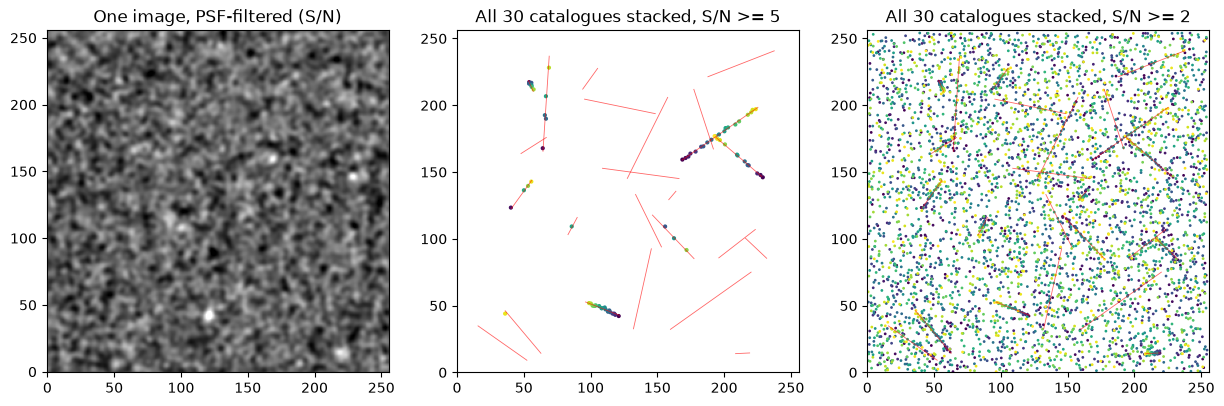

Red lines: the true tracks of the 24 injected objects (per-image S/N 1.0 - 5.0).


In [2]:
t, imgs, truth = sns.make_survey(N_EPOCHS, SIZE, A, T_SPAN, n_obj=24, snr_range=(1.0, 5.0), v_range=V_RANGE, seed=7)
cats = {nu: sns.detect(t, imgs, A, nu) for nu in (2.0, 3.0, 5.0)}
for nu, c in cats.items():
    print(f"threshold S/N >= {nu:.0f}: {c['x'].size:6,} detections in {N_EPOCHS} images")

fig, axs = plt.subplots(1, 3, figsize=(15, 4.8))
axs[0].imshow(sns.snr_image(imgs[0], A), origin="lower", cmap="gray", vmin=-3, vmax=5)
axs[0].set_title("One image, PSF-filtered (S/N)")
for ax, nu in zip(axs[1:], (5.0, 2.0)):
    c = cats[nu]
    ax.scatter(c["x"], c["y"], s=1 if nu < 3 else 4, c=c["t"], cmap="viridis")
    ax.set(xlim=(0, SIZE), ylim=(0, SIZE), aspect="equal", title=f"All {N_EPOCHS} catalogues stacked, S/N >= {nu:.0f}")
for k in range(len(truth["nu"])):
    for ax in axs[1:]:
        ax.plot([truth["x0"][k], truth["x0"][k] + truth["vx"][k] * T_SPAN], [truth["y0"][k], truth["y0"][k] + truth["vy"][k] * T_SPAN], color="r", lw=0.6, alpha=0.6)
plt.show()
print("Red lines: the true tracks of the 24 injected objects (per-image S/N "
      f"{truth['nu'].min():.1f} - {truth['nu'].max():.1f}).")

At S/N ≥ 5 the catalogue is pure but only the brightest objects appear, and even they appear only sometimes. At S/N ≥ 2 almost every detection is a noise peak, and the faint tracks are invisible by eye. Shift-and-stack must find them.

## 2. How many noise peaks?

The number of noise peaks sets everything else: how many detections must be stacked, and how likely a stack bin is to fill up by chance. S25 (their Sec. 2.2) take the surface density of noise peaks of height $z$ from Budavári, Szalay & Loredo (2017), for white noise and a Gaussian PSF. We can measure it directly in noise-only images, and compare with two versions of that formula: the expression as printed in S25, and Budavári et al.'s own (their Appendix, with their shape and scale parameters $\gamma^2 = 1/2$, $R^2 = a^2/2$).

 nu_th   measured   Budavari+17   S25 as printed   (noise peaks above nu_th per a^2)
 -2.0    4.43e-02     6.49e-02       8.55e-01
  0.0    4.20e-02     5.86e-02       7.91e-01
  1.0    2.85e-02     4.05e-02       5.36e-01
  1.5    1.78e-02     2.59e-02       3.74e-01
  2.0    8.77e-03     1.30e-02       2.32e-01
  2.5    3.27e-03     5.07e-03       1.27e-01
  3.0    9.19e-04     1.51e-03       6.17e-02
  3.5    2.04e-04     3.45e-04       2.66e-02
  4.0    4.14e-05     6.03e-05       1.02e-02


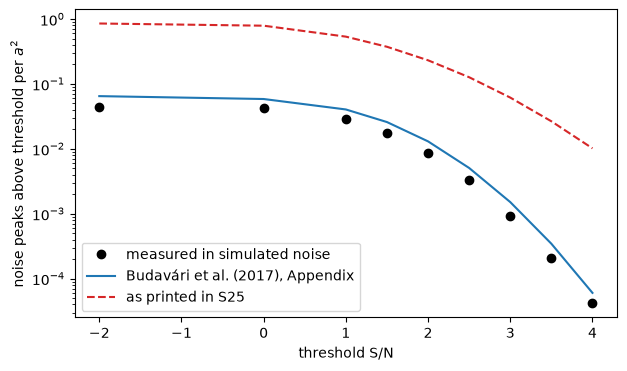

In [3]:
tn, noise, _ = sns.make_survey(40, 360, A, T_SPAN, n_obj=0, seed=3)
area = (360 - 2) ** 2 * 40
thresholds = np.array([-2, 0, 1, 1.5, 2, 2.5, 3, 3.5, 4])
measured = np.array([sns.detect(tn, noise, A, nu)["x"].size / area * A * A for nu in thresholds])
b17 = np.array([sns.peaks_above(nu, A) * A * A for nu in thresholds])
s25 = np.array([sns.peaks_above(nu, A, sns.peak_density_s25) * A * A for nu in thresholds])
print(" nu_th   measured   Budavari+17   S25 as printed   (noise peaks above nu_th per a^2)")
for row in zip(thresholds, measured, b17, s25):
    print(f"{row[0]:5.1f}  {row[1]:10.2e}  {row[2]:11.2e}  {row[3]:13.2e}")

fig, ax = plt.subplots(figsize=(7, 4))
ax.semilogy(thresholds, measured, "ko", label="measured in simulated noise")
ax.semilogy(thresholds, b17, "-", color="C0", label="Budavári et al. (2017), Appendix")
ax.semilogy(thresholds, s25, "--", color="C3", label="as printed in S25")
ax.set(xlabel="threshold S/N", ylabel="noise peaks above threshold per $a^2$")
ax.legend()
plt.show()

Our simulated noise peaks follow the *shape* of Budavári et al.'s distribution closely, but there are fewer of them at every threshold, by a factor of about 0.6 to 0.7 (we checked that this does not change with the PSF's size in pixels). The expression printed in S25 differs from Budavári et al.'s in its form as well as its normalisation, and overpredicts our counts by factors of 20 to 250. We have not tracked down the source of either difference; since our simulation is the ground truth for this notebook, we use the *measured* densities below. For orientation: at threshold 2 there are about 0.009 noise peaks per $a^2$, or roughly 140 per image here, so a catalogue of 30 images holds about 4,500 detections, almost all of them noise.

## 3. Choosing the bin size and the minimum count

For a trial velocity that matches an object, its detections all project to the same place, within their positional errors $\sigma = \sqrt2\,a/\nu$ (S25, after Portillo et al. 2020). S25 write the expected number of the object's detections that land in a stack bin of side $\Delta x$, over $N$ epochs, as

$$E[N_{\rm signal}] = N\,\tfrac12{\rm erfc}\!\left(\frac{\nu_{\rm th}-\nu}{\sqrt2}\right){\rm erf}^2\!\left(\frac{\Delta x\,\nu}{4a}\right),$$

while noise peaks land there at random, $E[N_{\rm noise}] = N\lambda(\nu_{\rm th})\,\Delta x^2$. A bigger bin catches more of the object's scattered detections but also more noise. We use the measured noise density $\lambda$ from Section 2 (S25 Fig. 2 analogue).

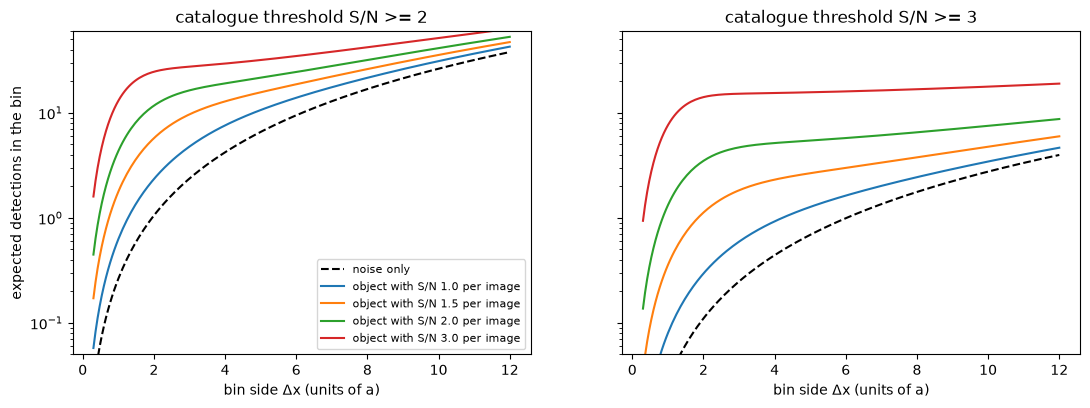

In [4]:
lam_measured = dict(zip(thresholds, measured))     # per a^2
dxs = np.linspace(0.3, 12, 200)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, nu_th in zip(axs, (2.0, 3.0)):
    noise_counts = N_EPOCHS * lam_measured[nu_th] * dxs**2
    ax.plot(dxs, noise_counts, "k--", lw=1.5, label="noise only")
    for nu, col in zip([1.0, 1.5, 2.0, 3.0], ["C0", "C1", "C2", "C3"]):
        sig = N_EPOCHS * 0.5 * special.erfc((nu_th - nu) / np.sqrt(2)) * special.erf(dxs * nu / 4) ** 2
        ax.plot(dxs, sig + noise_counts, color=col, label=f"object with S/N {nu} per image")
    ax.set(xlabel="bin side Δx (units of a)", title=f"catalogue threshold S/N >= {nu_th:.0f}", yscale="log", ylim=(0.05, 60))
axs[0].set_ylabel("expected detections in the bin")
axs[0].legend(fontsize=8)
plt.show()

The object stands out where its curve rises well above the dashed noise curve. At a threshold of 2, objects of S/N 1.5 per image barely do; at a threshold of 3 they hardly get into the catalogue at all. We use $\Delta x = 2a$ at threshold 2 and $\Delta x = 4a$ at threshold 3, and require $N_{\rm min} = 8$ detections in a bin.

## 4. The catalogue search

For each trial velocity $(v_x, v_y)$, every detection is projected back to the first epoch, $x_0 = x - v_x(t - t_0)$, and the projected positions are histogrammed in bins of $\Delta x$. Trial velocities must be spaced by no more than $\Delta x/\Delta t$, so that an object's detections stay within one bin (S25 Sec. 2); with coarser bins, fewer velocities are needed. The algorithm (S25 Sec. 2.1) then repeatedly takes the fullest bin of the joint histogram, removes its detections, and stops when the fullest bin holds fewer than $N_{\rm min}$.

Each cluster still contains some noise. S25 fit the track with a robust multivariate regression, using the Minimum Covariance Determinant (MCD) estimate of the mean and covariance of $(t, x, y)$ (Rousseeuw & Van Driessen 1999), which ignores up to half of the points as outliers. Here is the difference it makes for one cluster:

1,456 trial velocities, 46 clusters, 1.7 s


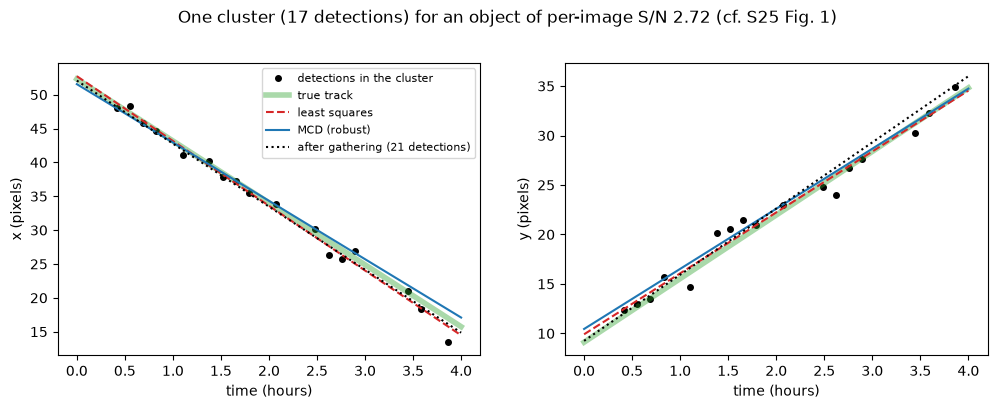

In [5]:
cat = cats[2.0]
t0_ = time.time()
res, n_vel = sns.catalog_search(cat, 2 * A, 1.5, 21.0, n_min=8, max_results=80, size=SIZE)
t_cat = time.time() - t0_
print(f"{n_vel:,} trial velocities, {len(res)} clusters, {t_cat:.1f} s")

# Among clusters that match an injected object, the one where least squares and the MCD differ most
best = None
for r in res:
    if len(r["members"]) < 8:
        continue
    ls_, rb_ = sns.fit_track(cat, r["members"], robust=False), sns.fit_track(cat, r["members"], robust=True)
    m = sns.matches(rb_, truth, t, 2 * A)
    if not m.size:
        continue
    diff = max(abs((ls_[0] + ls_[2] * T_SPAN) - (rb_[0] + rb_[2] * T_SPAN)), abs((ls_[1] + ls_[3] * T_SPAN) - (rb_[1] + rb_[3] * T_SPAN)))
    if best is None or diff > best[0]:
        best = (diff, r, m[0])
_, r, k = best
mem = r["members"]
ls = sns.fit_track(cat, mem, robust=False)
rb = sns.fit_track(cat, mem, robust=True)
g = sns.gather(cat, rb, 1.5 * A)
rf = sns.fit_track(cat, g)
tt = np.linspace(0, T_SPAN, 50)
fig, axs = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, coord, i in zip(axs, ["x", "y"], [0, 1]):
    ax.plot(cat["t"][mem], cat[coord][mem], "ko", ms=4, label="detections in the cluster")
    ax.plot(tt, [truth[f"{coord}0"][k] + truth[f"v{coord}"][k] * s for s in tt], color="C2", lw=4, alpha=0.4, label="true track")
    ax.plot(tt, ls[i] + ls[2 + i] * tt, "--", color="C3", label="least squares")
    ax.plot(tt, rb[i] + rb[2 + i] * tt, "-", color="C0", label="MCD (robust)")
    ax.plot(tt, rf[i] + rf[2 + i] * tt, ":", color="k", label=f"after gathering ({len(g)} detections)")
    ax.set(xlabel="time (hours)", ylabel=f"{coord} (pixels)")
axs[0].legend(fontsize=8)
fig.suptitle(f"One cluster ({len(mem)} detections) for an object of per-image S/N {truth['nu'][k]:.2f} (cf. S25 Fig. 1)", y=1.02)
plt.show()

Here, with a catalogue at threshold 2 and bins of $2a$, the clusters are fairly clean, so least squares and the MCD agree closely; the robust fit matters more when bins are larger or the threshold lower, and clusters collect more noise. After the robust fit, S25 gather all catalogue detections within $\Delta x$ of the fitted line and fit again. A track is matched to an injected object if they agree to within $2a$ in at least half of the epochs (S25 use 1″).

In [6]:
def unassociated(track, truth, radius=3 * A):
    # a false positive: a candidate track that never comes within 3a of any injected object.
    # (A bright object stacked at a slightly wrong velocity still peaks somewhere along its track.)
    x0, y0, vx, vy = track
    px, py = x0 + vx * t[:, None], y0 + vy * t[:, None]
    tx = truth["x0"][None, :] + truth["vx"][None, :] * t[:, None]
    ty = truth["y0"][None, :] + truth["vy"][None, :] * t[:, None]
    return np.hypot(px - tx, py - ty).min() > radius

def recover(cat, results, truth, gather_radius):
    found, n_false = set(), 0
    for r in results:
        trk = sns.fit_track(cat, r["members"])
        g = sns.gather(cat, trk, gather_radius)
        if len(g) >= 6:
            trk = sns.fit_track(cat, g)
        m = sns.matches(trk, truth, t, 2 * A)
        found |= set(m.tolist())
        n_false += unassociated(trk, truth)
    rec = np.zeros(len(truth["nu"]), bool)
    rec[list(found)] = True
    return rec, n_false

rec2, false2 = recover(cats[2.0], res, truth, 1.5 * A)
print(f"Catalogue S/N >= 2: recovered {rec2.sum()} of {rec2.size} objects; {false2} clusters never come near an injected object")

Catalogue S/N >= 2: recovered 20 of 24 objects; 16 clusters never come near an injected object


## 5. Against image-based shift-and-stack

The classical search shifts every PSF-filtered image back along each trial velocity, adds them, and looks for peaks in the stack, whose S/N grows as $\sqrt N$ times the per-image S/N. Its stack must line up to within a PSF, so its trial velocities are spaced by $a/\Delta t$, half the catalogue search's $2a/\Delta t$ in each direction (S25's image-based baseline also uses a bin of one PSF). With so many velocities × pixels, the largest pure-noise value in all the stacks is around 6 to 6.5σ, so we keep peaks above 7σ to hold false positives down.

To compare depths properly we need more objects than one survey holds, so we repeat everything on four independent surveys (96 objects).

In [7]:
rows = []
times = {"catalogue, S/N >= 2": 0.0, "catalogue, S/N >= 3": 0.0, "images": 0.0}
false = {k: 0 for k in times}
for seed in range(4):
    ts, ims, tru = sns.make_survey(N_EPOCHS, SIZE, A, T_SPAN, n_obj=24, snr_range=(0.8, 4.0), v_range=V_RANGE, seed=100 + seed)
    out = {"nu": tru["nu"]}
    for nu_th, dx, key in [(2.0, 2 * A, "catalogue, S/N >= 2"), (3.0, 4 * A, "catalogue, S/N >= 3")]:
        c = sns.detect(ts, ims, A, nu_th)
        t0_ = time.time()
        rs, _ = sns.catalog_search(c, dx, 1.5, 21.0, n_min=8, max_results=80, size=SIZE)
        rec, nf = recover(c, rs, tru, 1.5 * A)
        times[key] += time.time() - t0_
        out[key] = rec
        false[key] += nf
    cands, nv_img, dt_img = sns.image_search_peaks(ts, ims, A, 1.5, 21.0, A / T_SPAN, threshold=7.0)
    kept = sns.merge_candidates(cands, 3 * A, 1.0)
    found = set()
    for x0, y0, vx, vy, s in kept:
        m = sns.matches((x0, y0, vx, vy), tru, ts, 2 * A)
        found |= set(m.tolist())
        false["images"] += unassociated((x0, y0, vx, vy), tru)
    rec = np.zeros(24, bool); rec[list(found)] = True
    out["images"], times["images"] = rec, times["images"] + dt_img
    rows.append(out)
nu_all = np.concatenate([r["nu"] for r in rows])
print(f"image search: {nv_img:,} trial velocities per survey")
for key in times:
    rec = np.concatenate([r[key] for r in rows])
    print(f"{key:22s}: recovered {rec.sum():2d}/96, false candidates {false[key]:4d}, search time {times[key]:6.1f} s")
print(f"Speed-up of the S/N >= 2 catalogue search over the image search: {times['images'] / times['catalogue, S/N >= 2']:.0f}x")

image search: 5,660 trial velocities per survey
catalogue, S/N >= 2   : recovered 75/96, false candidates   73, search time    6.4 s
catalogue, S/N >= 3   : recovered 42/96, false candidates    0, search time    1.1 s
images                : recovered 78/96, false candidates   38, search time  105.6 s
Speed-up of the S/N >= 2 catalogue search over the image search: 17x


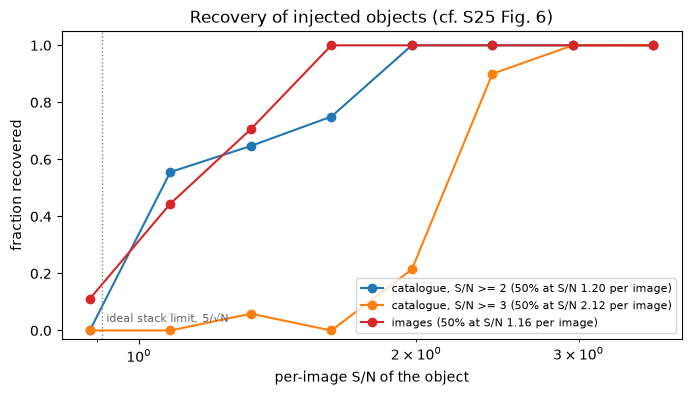

In [8]:
def nu50(nu, rec):
    # S25 Sec. 3.4.1: completeness c / (1 + exp(k (m - m50))), here in m = -2.5 log10(nu); fit by maximum likelihood
    from scipy.optimize import minimize
    m = -2.5 * np.log10(nu)
    def nll(p):
        c, k, m50 = 1 / (1 + np.exp(-p[0])), np.exp(p[1]), p[2]
        pr = np.clip(c / (1 + np.exp(k * (m - m50))), 1e-9, 1 - 1e-9)
        return -np.sum(np.where(rec, np.log(pr), np.log(1 - pr)))
    best = min((minimize(nll, [3, np.log(5), m0], method="Nelder-Mead") for m0 in (-1.0, -0.5, 0.0)), key=lambda r: r.fun)
    return 10 ** (-best.x[2] / 2.5)

fig, ax = plt.subplots(figsize=(8, 4))
bins = np.geomspace(0.8, 4.0, 9)
mid = np.sqrt(bins[1:] * bins[:-1])
for key, col in zip(times, ["C0", "C1", "C3"]):
    rec = np.concatenate([r[key] for r in rows])
    frac = [rec[(nu_all >= lo) & (nu_all < hi)].mean() for lo, hi in zip(bins[:-1], bins[1:])]
    n50 = nu50(nu_all, rec)
    ax.plot(mid, frac, "o-", color=col, label=f"{key} (50% at S/N {n50:.2f} per image)")
ax.axvline(5 / np.sqrt(N_EPOCHS), color="0.5", ls=":", lw=1)
ax.text(5 / np.sqrt(N_EPOCHS), 0.03, " ideal stack limit, 5/√N", color="0.4", fontsize=8)
ax.set(xscale="log", xlabel="per-image S/N of the object", ylabel="fraction recovered", ylim=(-0.03, 1.05),
       title="Recovery of injected objects (cf. S25 Fig. 6)")
ax.legend(fontsize=8)
plt.show()

The patterns match S25's:

* **Depth.** Searching a catalogue thresholded at S/N 2 reaches almost as deep as stacking the images: 50% completeness at a per-image S/N of about 1.2, against about 1.16 for the image search, a difference of only a few hundredths of a magnitude in this simulation (S25 found 0.25 mag for their real data and settings). Both are far below the S/N of 5 needed for a single-image detection, and within about 30% of the ideal stack limit $5/\sqrt{30}\approx0.9$. A catalogue thresholded at S/N 3 loses the faintest objects, because they rarely reach 3 in a single image.
* **Purity.** Both searches return some false candidates; the catalogue search at threshold 2 returns more, because chance clusters of noise peaks are common at that density. At threshold 3 it returned none. Raising $N_{\rm min}$ trades depth for purity, the trade-off S25 explore in their Figs. 7 and 8.
* **Speed.** The catalogue search was about 20 times faster than the image search on the same images, even here, where the images are small and the objects slow. S25 find speed-ups of 10 to 1000 on real data; the gain grows with the number of trial velocities.

## Summary

* Thresholding single images at S/N 5 misses objects far brighter than a stack could find. Shift-and-stack reaches about $\sqrt N$ deeper, at a high computational cost.
* S25's catalogue version stacks low-threshold detections instead of pixels: project every detection to a reference time for each trial velocity, histogram, and peel off the fullest bins, then fit each cluster with a robust (MCD) regression.
* Noise-peak statistics set the bin size and the minimum cluster size; our simulated noise peaks follow the theory's shape, but not the normalisation of either published form, so we used measured densities.
* On a simulated 30-image, 4-hour survey, searching an S/N ≥ 2 catalogue recovered objects nearly as faint as image-based shift-and-stack (50% completeness at a per-image S/N of about 1.2), about 20 times faster.

## Going further

* **Faster objects.** The number of trial velocities grows as $(\Delta t\,\Delta v/\Delta x)^2$. Try main-belt speeds (hundreds of pixels per hour) and watch the image-based search's cost explode while the catalogue search's grows more slowly.
* **Real artefacts.** Real difference images contain poorly subtracted stars and other artefacts that cluster in place. S25 discuss how these contaminate the catalogue search.
* **Lower thresholds.** S25 search catalogues down to S/N 1, where the noise density, and the memory needed, rise steeply.

## References

* Budavári, T., Szalay, A. S. & Loredo, T. J. 2017, *Faint Object Detection in Multi-epoch Observations via Catalog Data Fusion*, ApJ 838, 52. [ADS](https://ui.adsabs.harvard.edu/abs/2017ApJ...838...52B/abstract)
* Portillo, S. K. N., Speagle, J. S. & Finkbeiner, D. P. 2020, *Photometric Biases in Modern Surveys*, AJ 159, 165. [ADS](https://ui.adsabs.harvard.edu/abs/2020AJ....159..165P/abstract)
* Rousseeuw, P. J. & Van Driessen, K. 1999, *A Fast Algorithm for the Minimum Covariance Determinant Estimator*, Technometrics 41, 212.
* Stetzler, S., Jurić, M., Bernardinelli, P. H. et al. 2025, *An Efficient Shift-and-stack Algorithm Applied to Detection Catalogs*, AJ 170, 352. [ADS](https://ui.adsabs.harvard.edu/abs/2025AJ....170..352S/abstract)